# Wave analysis

Santolik et al. (2003) proposed a method for analyzing wave data in space plasmas, which is based on the singular value decomposition (SVD) of the spectral matrix of the observed wave field. This method allows for the identification of the dominant wave modes and their properties, such as polarization and propagation direction.   

Wave Polarization Analyzed by Singular Value Decomposition of the Spectral Matrix in the Presence of Noise  Ulrich Taubenschuss1 · Ondřej Santolík



In [7]:
import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import pandas as pd
import glob 
import os
import pickle
import pywt #PyWavelets package
import matplotlib.colors as colors

# importing the pdr module itself is mandatory for most uses of pdr.
import pdr  
from data_process import select_df,fac_decompose_dB,read_and_process_data,detrend_data


## wave normal angle and eccentricity

First test the method on generated data

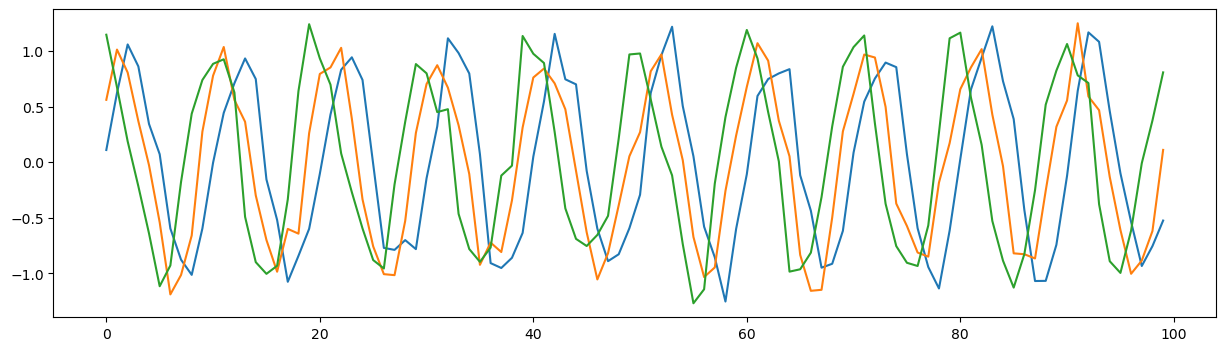

In [8]:
# generate test data
fs= 1
t = np.arange(0, 100, 1/fs)
f1 = 0.1
Bx= np.sin(2 * np.pi * f1 * t) + 0.15 * np.random.normal(size=t.shape)
By= np.sin(2 * np.pi * f1 * t + np.pi/4) + 0.15 * np.random.normal(size=t.shape)
Bz= np.sin(2 * np.pi * f1 * t + np.pi/2) + 0.15 * np.random.normal(size=t.shape)

fig,ax=plt.subplots(1,1,figsize=(15,4))
ax.plot(t,Bx,label='Bx')
ax.plot(t,By,label='By')
ax.plot(t,Bz,label='Bz')

N: 100


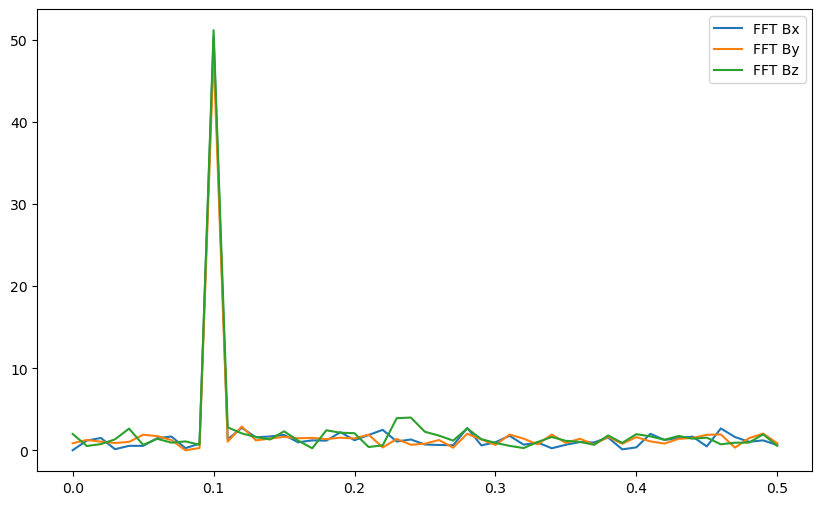

In [9]:
# FFT
N=len(t)
print("N:",N)

# real input, use rfft
fft_Bx = fft.rfft(Bx)
fft_By = fft.rfft(By)
fft_Bz = fft.rfft(Bz)
freqs = fft.rfftfreq(N, 1/fs)

# plot FFT
fig,ax=plt.subplots(1,1,figsize=(10,6))
ax.plot(freqs, np.abs(fft_Bx), label='FFT Bx')
ax.plot(freqs, np.abs(fft_By), label='FFT By')
ax.plot(freqs, np.abs(fft_Bz), label='FFT Bz')
ax.legend()

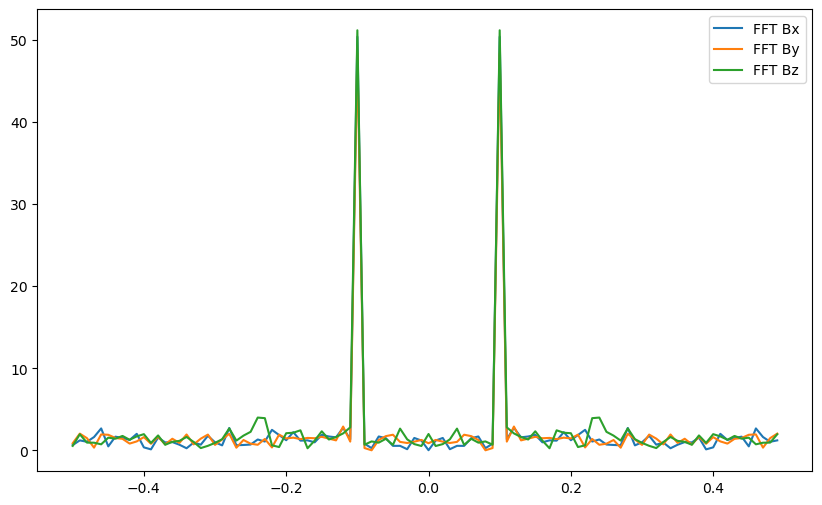

In [10]:
# if fft is used
fft_Bx = fft.fft(Bx)
fft_By = fft.fft(By)
fft_Bz = fft.fft(Bz)
freqs = fft.fftfreq(N, 1/fs)

fft_Bx = fft.fftshift(fft_Bx)
fft_By = fft.fftshift(fft_By)
fft_Bz = fft.fftshift(fft_Bz)
freqs = fft.fftshift(freqs)

# plot FFT
fig,ax=plt.subplots(1,1,figsize=(10,6))
ax.plot(freqs, np.abs(fft_Bx), label='FFT Bx')
ax.plot(freqs, np.abs(fft_By), label='FFT By')
ax.plot(freqs, np.abs(fft_Bz), label='FFT Bz')
ax.legend()

In [11]:
idx=np.argmax(np.abs(fft_Bx))
freq=freqs[idx]
print("Peak frequency:",freq)

Peak frequency: -0.1


In [12]:
print(fft_Bx[idx],fft_By[idx],fft_Bz[idx])

(-2.097733149666457+50.35075905670264j) (34.70335402625324+33.68863680801175j) (51.16998029770724-1.2551909268253145j)


In [14]:
B_vec=np.array([fft_Bx[idx],fft_By[idx],fft_Bz[idx]])

In [ ]:
# J = Bi * Bj*
J=

In [22]:
B_vec.reshape((3,1)) @ B_vec.reshape((1,3))

array([[-2530.79845322 -211.24491277j, -1769.04681101+1676.67044684j,
          -44.14114801+2579.08040452j],
       [-1769.04681101+1676.67044684j,    69.39853069+2338.21737962j,
         1818.05561305+1680.28754662j],
       [  -44.14114801+2579.08040452j,  1818.05561305+1680.28754662j,
         2616.7913794  -128.45618999j]])